# Industry Project: Choosing a Model with Evidence, Champion vs Challenger (Production-Style)

> **Who is this notebook for?** Beginners who can train a few models and now wonder: *"Model B scored 0.01 higher than model A. Should we replace A?"*
> This notebook shows how teams answer that question with **honest validation, confidence intervals, statistical tests, business cost and engineering constraints**. Every step is explained in plain English.

---

### How this notebook is different from the other notebooks in `06_model_evaluation/`

| `01_model_evaluation.ipynb` / `02_hyperparameter_optimization.ipynb` | This notebook |
|---|---|
| What metrics and CV schemes **are** | Which validation scheme **predicts production** for *this* data |
| One score per model | Scores with **confidence intervals** from repeated CV and the bootstrap |
| "Higher is better" | **Is the difference real?** Corrected paired t-test and paired bootstrap |
| ROC-AUC, F1, ... | A metric tied to **dollars** (cost of calls vs cost of late payments) |
| Tuning hyperparameters | A **champion/challenger decision** that also weighs latency, size and interpretability, with a written **selection report** |

---

### The business problem

You work at a B2B wholesaler that sends ~600 invoices per month. Some customers pay **late**, which costs money (financing the gap, admin work, sometimes a write-off).

- The **collections team** can call a customer *before* the due date. A call costs about **$25** of staff time.
- A late invoice costs on average **$200**. A call prevents about **35%** of late payments.
- Today a **logistic regression** ("the champion") picks whom to call. A data scientist built a **gradient-boosting model** ("the challenger") that looks better in a notebook.

**Your job:** decide, with evidence, whether the challenger should replace the champion, and write the decision down so that others can review it.

---

### Table of Contents
1. Setup: imports, config and the selection policy
2. The data: two years of invoices
3. Hold out the future: development period vs out-of-time test
4. The candidate models
5. Which validation scheme can we trust? Random vs grouped vs time-based CV
6. Repeated CV and confidence intervals
7. Is the challenger really better? Paired statistical tests
8. A metric tied to money: expected cost per 1,000 invoices
9. Out-of-time test with a paired bootstrap
10. Segment check: does any customer group get worse?
11. Engineering constraints: latency, size, interpretability
12. The champion/challenger decision and the selection report
13. Automated checks
14. Summary, exercises and resources

---
## 1. Setup: imports, config and the selection policy

A professional team writes down the **selection policy before looking at the results**. Otherwise it is too tempting to move the goalposts ("ok, it's slower, but look at that AUC!"). Our policy is a small dataclass.

In [1]:
# ---- Standard library ----
import json
import logging
import pickle                    # measure model size in bytes
import tempfile                  # temporary folder for the report (never write into the repo)
import time
import warnings
from dataclasses import dataclass, asdict
from datetime import datetime, timezone
from pathlib import Path

# ---- Third-party ----
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from scipy import stats                                     # t-distribution for the statistical test
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, KFold, TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits       # control CPU threads used by NumPy / OpenMP

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
log = logging.getLogger("model_selection")

# Use ONE CPU thread for the numeric libraries. On a shared server (CI runner, notebook server, a laptop
# running other jobs) multi-threaded gradient boosting can become many times SLOWER because threads fight
# for the CPU. For datasets of this size one thread is fast enough; raise it on a dedicated machine.
threadpool_limits(limits=1)


@dataclass(frozen=True)
class Config:
    random_state: int = 42
    n_customers: int = 1_500
    n_months: int = 24
    test_months: int = 6                    # last 6 months = out-of-time test
    cost_call_usd: float = 25.0             # one collections call
    cost_late_usd: float = 200.0            # one late invoice
    call_success_rate: float = 0.35         # share of late payments a call prevents
    cv_folds: int = 5
    cv_repeats: int = 5                     # 5 x 5 = 25 paired scores
    n_bootstrap: int = 1000


@dataclass(frozen=True)
class SelectionPolicy:
    """Written BEFORE looking at results. The challenger must pass ALL rules."""
    min_saving_per_1000_invoices_usd: float = 300.0   # smaller gains are not worth a migration
    require_ci_above_zero: bool = True                  # the 95% CI of the saving must exclude 0
    max_p95_latency_ms: float = 100.0                   # the invoicing system calls the model online
    max_model_size_mb: float = 50.0
    max_segment_auc_drop: float = 0.03                  # no large segment (>= 1,000 invoices) may get clearly worse


CFG, POLICY = Config(), SelectionPolicy()
log.info("scikit-learn %s", sklearn.__version__)
print(CFG); print(POLICY)

2026-10-21 17:58:24,346 | INFO | scikit-learn 1.9.0


Config(random_state=42, n_customers=1500, n_months=24, test_months=6, cost_call_usd=25.0, cost_late_usd=200.0, call_success_rate=0.35, cv_folds=5, cv_repeats=5, n_bootstrap=1000)
SelectionPolicy(min_saving_per_1000_invoices_usd=300.0, require_ci_above_zero=True, max_p95_latency_ms=100.0, max_model_size_mb=50.0, max_segment_auc_drop=0.03)


---
## 2. The data: two years of invoices

In real life this is a SQL query over the ERP system (SAP, Oracle, NetSuite). Here we **simulate** it. The hidden truth contains things real invoice data has:
- **customers differ** (some always pay late), and each customer sends **many invoices** (so invoices are not independent),
- **non-linear effects** (a credit score below ~580 and the first 3 months of a new customer are much riskier; large invoices matter only for small companies), which tree models can capture better,
- a **change over time**: in the last 6 months, a funding crunch hit **tech** and **healthcare** customers (so far reliable payers), who suddenly pay late much more often, while construction improves (**concept drift**). A model trained on the past ranks these customers wrongly.

`prior_late_rate` is a point-in-time feature: the share of this customer's *earlier* invoices that were paid late.

23,780 invoices from 1,498 customers; late rate 24.8%


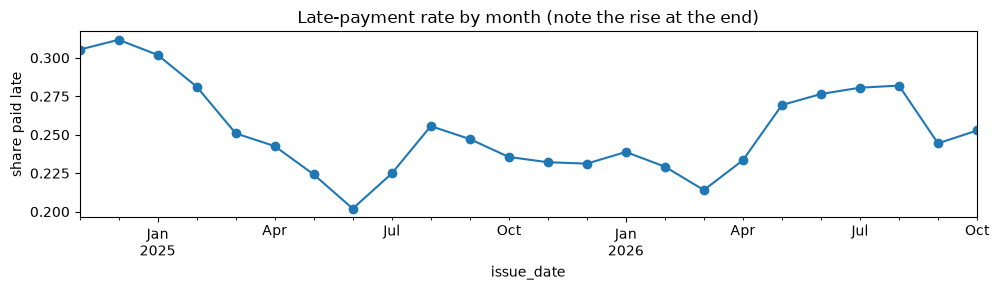

In [2]:
def simulate_invoices(cfg: Config = CFG) -> pd.DataFrame:
    rng = np.random.default_rng(cfg.random_state)
    industries = np.array(["retail", "construction", "manufacturing", "tech", "healthcare", "hospitality"])
    cust = pd.DataFrame({
        "customer_id": [f"C{i:04d}" for i in range(cfg.n_customers)],
        "industry": rng.choice(industries, cfg.n_customers, p=[.22, .16, .2, .16, .12, .14]),
        "company_size": rng.choice(["small", "medium", "large"], cfg.n_customers, p=[.5, .35, .15]),
        "region": rng.choice(["north", "south", "east", "west"], cfg.n_customers),
        "credit_score": rng.normal(660, 70, cfg.n_customers).clip(350, 850).round(),
        # month in which they became a customer: most are long-standing, some are new
        "first_month": np.minimum(rng.exponential(5, cfg.n_customers).astype(int), cfg.n_months - 3),
    })
    latent = rng.normal(0, 1.2, cfg.n_customers)                                   # hidden payment habits
    rows = []
    for i, c in cust.iterrows():
        per_month = 0.6 if c.company_size == "small" else 1.0                    # average invoices per month
        for m in range(c.first_month, cfg.n_months):
            rows.extend([(i, m)] * rng.poisson(per_month))
    inv = pd.DataFrame(rows, columns=["cust_idx", "month"])
    inv = inv.join(cust, on="cust_idx")
    size_mult = inv["company_size"].map({"small": 1.0, "medium": 3.0, "large": 8.0})
    inv["amount"] = (rng.lognormal(7.2, 0.8, len(inv)) * size_mult).round(2)
    inv["payment_terms_days"] = rng.choice([30, 60, 90], len(inv), p=[.6, .3, .1])
    inv["issue_date"] = pd.Timestamp("2024-11-01") + pd.to_timedelta(inv["month"] * 30 + rng.integers(0, 30, len(inv)), unit="D")
    inv["tenure_months"] = inv["month"] - inv["first_month"]

    drift = inv["month"] >= cfg.n_months - cfg.test_months                          # the economy changes
    logit = (-1.8 + latent[inv["cust_idx"]]
             + 1.2 * (inv["credit_score"] < 580) - 0.003 * (inv["credit_score"] - 660)          # threshold effect
             + 0.5 * np.log(inv["amount"] / inv["amount"].median()) * (inv["company_size"] == "small")  # interaction
             + 0.3 * (inv["payment_terms_days"] == 90) + 0.8 * (inv["tenure_months"] < 3)       # new customers
             + inv["industry"].map({"construction": 0.4, "hospitality": 0.3, "retail": 0.1}).fillna(0)
             # drift: tech and healthcare (so far reliable payers) suddenly pay late more, construction improves
             + drift * 1.5 * inv["industry"].map({"tech": 1.0, "healthcare": 0.8, "construction": -0.4}).fillna(0))
    inv["paid_late"] = rng.binomial(1, 1 / (1 + np.exp(-logit)))

    inv = inv.sort_values(["issue_date"]).reset_index(drop=True)
    g = inv.groupby("customer_id")["paid_late"]
    inv["prior_invoices"] = g.cumcount()                                            # earlier invoices only
    inv["prior_late_rate"] = g.transform(lambda s: s.shift(1).expanding().mean())  # NaN for the first invoice
    inv["invoice_id"] = [f"INV{i:06d}" for i in range(len(inv))]
    cols = ["invoice_id", "issue_date", "customer_id", "industry", "company_size", "region", "credit_score",
            "amount", "payment_terms_days", "tenure_months", "prior_invoices", "prior_late_rate", "paid_late"]
    return inv[cols]


invoices = simulate_invoices()
monthly = invoices.groupby(invoices["issue_date"].dt.to_period("M"))["paid_late"].mean()
print(f"{len(invoices):,} invoices from {invoices['customer_id'].nunique():,} customers; late rate {invoices['paid_late'].mean():.1%}")
fig, ax = plt.subplots(figsize=(10, 3))
monthly.plot(ax=ax, marker="o"); ax.set_ylabel("share paid late"); ax.set_title("Late-payment rate by month (note the rise at the end)")
plt.tight_layout(); plt.show()

---
## 3. Hold out the future: development period vs out-of-time test

We lock away the **last 6 months** as the out-of-time test. It plays the role of "production": newer invoices, new customers, and the drift. Everything before is the **development period**, where we do all comparisons and choices.

In [3]:
test_start = invoices["issue_date"].max() - pd.DateOffset(months=CFG.test_months)
dev = invoices[invoices["issue_date"] < test_start].reset_index(drop=True)
oot = invoices[invoices["issue_date"] >= test_start].reset_index(drop=True)    # out-of-time test

FEATURES = ["industry", "company_size", "region", "credit_score", "amount", "payment_terms_days",
            "tenure_months", "prior_invoices", "prior_late_rate"]
X_dev, y_dev, groups_dev = dev[FEATURES], dev["paid_late"], dev["customer_id"]
X_oot, y_oot = oot[FEATURES], oot["paid_late"]

print(f"Development: {len(dev):,} invoices, late rate {y_dev.mean():.1%}")
print(f"Out-of-time: {len(oot):,} invoices, late rate {y_oot.mean():.1%}")
print(f"Customers in the OOT test that were never seen in development: {(~oot['customer_id'].isin(dev['customer_id'])).mean():.1%} of OOT invoices")

Development: 16,489 invoices, late rate 24.0%
Out-of-time: 7,291 invoices, late rate 26.8%
Customers in the OOT test that were never seen in development: 2.5% of OOT invoices


---
## 4. The candidate models

All candidates share the **same preprocessing** so that differences come from the model only:
- **Champion**: logistic regression (in production today; simple, fast, explainable).
- **Challenger**: `HistGradientBoostingClassifier` (strong on tabular data, captures non-linear effects).
- **Alternative**: `RandomForestClassifier` (another popular choice, but large and slower to serve).

Hyperparameters were chosen beforehand (see `02_hyperparameter_optimization.ipynb`); here we focus on **comparison**, not tuning.

In [4]:
CATEGORICAL = ["industry", "company_size", "region"]
NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]


def make_preprocessor() -> ColumnTransformer:
    numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),   # first invoice: no prior_late_rate
                        ("scale", StandardScaler())])                                      # needed by logistic regression
    return ColumnTransformer([("num", numeric, NUMERIC),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)])


CANDIDATES = {
    "champion_logreg": LogisticRegression(C=1.0, max_iter=1000),
    "challenger_hgb": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=15,
                                                     min_samples_leaf=50, random_state=CFG.random_state),
    "alt_random_forest": RandomForestClassifier(n_estimators=150, max_features=0.5, n_jobs=1,   # fully grown trees
                                                random_state=CFG.random_state),
}


def make_model(name: str) -> Pipeline:
    """A fresh, unfitted pipeline for the named candidate."""
    return Pipeline([("prep", make_preprocessor()), ("model", clone(CANDIDATES[name]))])


make_model("challenger_hgb")

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

---
## 5. Which validation scheme can we trust? Random vs grouped vs time-based CV

A validation scheme is only useful if its score **predicts what happens in production**. We compare three schemes on the development period, and then check which one came closest to the real out-of-time score:

| Scheme | How it splits | Risk |
|---|---|---|
| `KFold(shuffle=True)` | invoices at random | the same customer is in train **and** validation, so the model can "recognise" customers (e.g. by their exact credit score) |
| `GroupKFold` by customer | each customer is entirely in train or in validation | mimics *new* customers, but ignores time |
| `TimeSeriesSplit` | train on earlier months, validate on later ones | mimics production best, but fewer and smaller folds |

> Note: the invoices must be sorted by time for `TimeSeriesSplit` to make sense (we sorted them in the simulator).

In [5]:
schemes = {
    "random KFold": (KFold(n_splits=CFG.cv_folds, shuffle=True, random_state=CFG.random_state), None),
    "GroupKFold (customer)": (GroupKFold(n_splits=CFG.cv_folds, shuffle=True, random_state=CFG.random_state), groups_dev),
    "TimeSeriesSplit": (TimeSeriesSplit(n_splits=CFG.cv_folds), None),
}

t0 = time.perf_counter()
rows = []
fitted = {}
for name in CANDIDATES:
    row = {"model": name}
    for scheme_name, (cv, groups) in schemes.items():
        row[scheme_name] = cross_val_score(make_model(name), X_dev, y_dev, groups=groups, cv=cv, scoring="roc_auc").mean()
    fitted[name] = make_model(name).fit(X_dev, y_dev)                     # train on the whole development period
    row["OOT test (truth)"] = roc_auc_score(y_oot, fitted[name].predict_proba(X_oot)[:, 1])
    rows.append(row)
log.info("Validation-scheme comparison done in %.0fs", time.perf_counter() - t0)
scheme_table = pd.DataFrame(rows).set_index("model")
print(scheme_table.round(4))
print("\nOptimism = CV estimate - OOT truth (smaller is more honest):")
print(scheme_table.drop(columns="OOT test (truth)").sub(scheme_table["OOT test (truth)"], axis=0).round(4))

2026-10-21 18:01:22,141 | INFO | Validation-scheme comparison done in 173s


                   random KFold  GroupKFold (customer)  TimeSeriesSplit  \
model                                                                     
champion_logreg          0.7323                 0.7313           0.7337   
challenger_hgb           0.7482                 0.7468           0.7422   
alt_random_forest        0.7219                 0.7080           0.7178   

                   OOT test (truth)  
model                                
champion_logreg              0.7120  
challenger_hgb               0.7372  
alt_random_forest            0.6954  

Optimism = CV estimate - OOT truth (smaller is more honest):
                   random KFold  GroupKFold (customer)  TimeSeriesSplit
model                                                                  
champion_logreg          0.0203                 0.0193           0.0217
challenger_hgb           0.0111                 0.0096           0.0050
alt_random_forest        0.0265                 0.0126           0.0224


**How to read this:**
- Every CV scheme is **optimistic** compared with the out-of-time truth (by about 0.01-0.03 AUC), because the future contains drift (tech and healthcare suddenly paying late) that no scheme built on the past can see. That is normal, and it is why the final word always belongs to an out-of-time test (and later, to monitoring in production).
- **Random KFold is the worst offender for the random forest**: its fully grown trees memorise individual customers (e.g. by their exact credit score), and with random folds the same customer sits in training and validation. Random KFold rates the forest ~0.014 higher than grouped CV does. Logistic regression and the regularised boosting model (`min_samples_leaf=50`) cannot memorise single customers, so for them the three schemes agree within ~0.01.
- All schemes agree on the **ranking** (boosting > logistic regression > random forest), and the OOT test confirms it. That is the most important thing a validation scheme must get right.
- For this problem (repeat customers + time), we use **GroupKFold by customer** for the statistical comparison below (it gives many folds of decent size and cannot be fooled by memorised customers) and keep the OOT test for the final check.

---
## 6. Repeated CV and confidence intervals

A single 5-fold CV gives 5 scores, and they depend on how the folds happened to be cut. **Repeating** the CV with different shuffles (here 5 × 5 = 25 scores) gives a more stable mean and lets us compute an **uncertainty**.

Important: we use the **same folds for both models** (same seeds). This makes the comparison **paired**: in each fold both models face exactly the same invoices, so we can look at the *difference* per fold, which removes a lot of noise.

2026-10-21 18:01:46,036 | INFO | Repeated CV done in 24s


champion_logreg    ROC-AUC 0.7304  naive 95% CI [0.7254, 0.7354]  (fold std 0.0121)
challenger_hgb     ROC-AUC 0.7461  naive 95% CI [0.7415, 0.7507]  (fold std 0.0112)


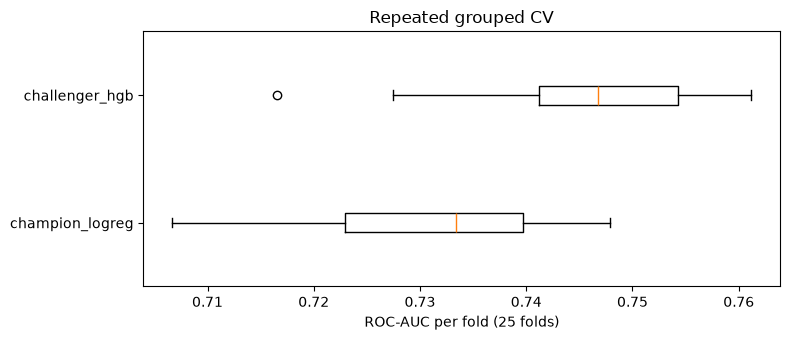

In [6]:
def repeated_group_cv(name: str) -> np.ndarray:
    """25 ROC-AUC scores: 5 repeats x 5 grouped folds, identical folds for every model (paired)."""
    scores = []
    for repeat in range(CFG.cv_repeats):
        cv = GroupKFold(n_splits=CFG.cv_folds, shuffle=True, random_state=repeat)     # seed = repeat id
        scores.extend(cross_val_score(make_model(name), X_dev, y_dev, groups=groups_dev, cv=cv,
                                      scoring="roc_auc", n_jobs=1))
    return np.array(scores)


t0 = time.perf_counter()
cv_scores = {name: repeated_group_cv(name) for name in ["champion_logreg", "challenger_hgb"]}
log.info("Repeated CV done in %.0fs", time.perf_counter() - t0)


def mean_ci(values, confidence=0.95):
    """Mean and a simple t-based confidence interval (treats the scores as independent: see Section 7!)."""
    m, se = values.mean(), values.std(ddof=1) / np.sqrt(len(values))
    h = se * stats.t.ppf((1 + confidence) / 2, len(values) - 1)
    return m, m - h, m + h


for name, s in cv_scores.items():
    m, lo, hi = mean_ci(s)
    print(f"{name:18s} ROC-AUC {m:.4f}  naive 95% CI [{lo:.4f}, {hi:.4f}]  (fold std {s.std(ddof=1):.4f})")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores), vert=False)
ax.set_xlabel("ROC-AUC per fold (25 folds)"); ax.set_title("Repeated grouped CV")
plt.tight_layout(); plt.show()

The boxes overlap. But overlapping boxes do **not** mean "no difference": the folds are paired, so the right question is about the **per-fold difference**.

---
## 7. Is the challenger really better? Paired statistical tests

We look at `diff = AUC(challenger) - AUC(champion)` for each of the 25 folds.

**The naive paired t-test is wrong here.** It assumes the 25 differences are independent. They are not: the training sets of different folds overlap heavily (each model is trained on ~80% of the same data), so the differences are correlated and the naive test is **over-confident** (too many "significant" results).

**Nadeau & Bengio's corrected resampled t-test** fixes this by inflating the variance:

$$ t = \frac{\overline{d}}{\sqrt{\left(\frac{1}{k} + \frac{n_{test}}{n_{train}}\right)\hat\sigma^2_d}} $$

where *k* = 25 folds, and $n_{test}/n_{train}$ ≈ 1/4 for 5-fold CV. This is the test used in the scikit-learn example *"Statistical comparison of models using grid search"*.

In [7]:
def corrected_paired_ttest(diffs: np.ndarray, n_train: int, n_test: int):
    """Nadeau-Bengio corrected resampled t-test. Returns (t statistic, two-sided p-value)."""
    k = len(diffs)
    corrected_var = (1 / k + n_test / n_train) * diffs.var(ddof=1)   # the correction term n_test/n_train
    t_stat = diffs.mean() / np.sqrt(corrected_var)
    p_value = 2 * stats.t.sf(abs(t_stat), df=k - 1)
    return t_stat, p_value


diffs = cv_scores["challenger_hgb"] - cv_scores["champion_logreg"]
n_test = len(X_dev) // CFG.cv_folds
n_train = len(X_dev) - n_test

naive_t, naive_p = stats.ttest_rel(cv_scores["challenger_hgb"], cv_scores["champion_logreg"])
corr_t, corr_p = corrected_paired_ttest(diffs, n_train, n_test)
wins = (diffs > 0).mean()

print(f"Mean AUC difference (challenger - champion): {diffs.mean():+.4f}")
print(f"Challenger wins in {wins:.0%} of the 25 folds")
print(f"Naive paired t-test     : t = {naive_t:6.2f}, p = {naive_p:.2g}")
print(f"Corrected (Nadeau-Bengio): t = {corr_t:6.2f}, p = {corr_p:.2g}")

Mean AUC difference (challenger - champion): +0.0157
Challenger wins in 100% of the 25 folds
Naive paired t-test     : t =  13.20, p = 1.7e-12
Corrected (Nadeau-Bengio): t =   4.90, p = 5.3e-05


Compare the two p-values: the corrected test is **much less confident** than the naive one (its t statistic is roughly 2.7× smaller). Here the challenger wins in every fold and the difference stays clearly significant even after the correction, but with a smaller or noisier gap the naive test would often shout "significant" when the corrected one does not. Always report the corrected version when comparing models with (repeated) cross-validation.

And remember: a *statistically* significant AUC difference can still be *practically* irrelevant. 0.005 AUC might be "real" yet worth nothing to the business. That is why the next step converts predictions into **dollars**.

---
## 8. A metric tied to money: expected cost per 1,000 invoices

ROC-AUC measures **ranking quality**, but the collections team needs a **decision**: call or don't call. The decision rule is a **threshold** on the predicted probability, and the right metric is the **cost** of those decisions:

| Decision | Invoice paid late | Invoice paid on time |
|---|---|---|
| Call | $25 + 65% × $200 (the call prevents 35%) | $25 (wasted call) |
| Don't call | $200 | $0 |

Simple arithmetic gives the break-even: call when `p × 0.35 × $200 > $25`, i.e. **p > 0.36**. This only works if the probabilities are **calibrated**, so we also choose each model's threshold empirically on **out-of-fold predictions from the development period** (never on the test set).

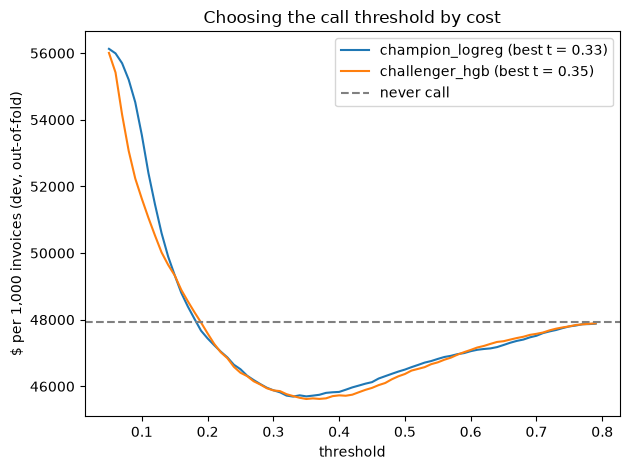

champion_logreg    best threshold 0.33 -> $45,693 per 1,000 invoices
challenger_hgb     best threshold 0.35 -> $45,620 per 1,000 invoices
never call                             -> $47,923 per 1,000 invoices


In [8]:
from sklearn.model_selection import cross_val_predict


def cost_per_1000(y_true, proba, threshold, cfg=CFG) -> float:
    """Average total cost (calls + late payments) per 1,000 invoices for a call-if-p>=threshold rule."""
    y_true = np.asarray(y_true)
    call = proba >= threshold
    cost = np.where(call, cfg.cost_call_usd + y_true * cfg.cost_late_usd * (1 - cfg.call_success_rate),
                    y_true * cfg.cost_late_usd)
    return 1000 * cost.mean()


thresholds = np.round(np.arange(0.05, 0.8, 0.01), 2)
oof_cv = GroupKFold(n_splits=CFG.cv_folds, shuffle=True, random_state=0)
best_threshold, oof_proba = {}, {}
for name in ["champion_logreg", "challenger_hgb"]:
    oof_proba[name] = cross_val_predict(make_model(name), X_dev, y_dev, groups=groups_dev, cv=oof_cv,
                                        method="predict_proba")[:, 1]
    costs = [cost_per_1000(y_dev, oof_proba[name], t) for t in thresholds]
    best_threshold[name] = float(thresholds[int(np.argmin(costs))])
    plt.plot(thresholds, costs, label=f"{name} (best t = {best_threshold[name]:.2f})")
no_calls = cost_per_1000(y_dev, np.zeros(len(y_dev)), 1.0)
plt.axhline(no_calls, color="grey", ls="--", label="never call")
plt.xlabel("threshold"); plt.ylabel("$ per 1,000 invoices (dev, out-of-fold)"); plt.legend()
plt.title("Choosing the call threshold by cost"); plt.tight_layout(); plt.show()

for name in best_threshold:
    print(f"{name:18s} best threshold {best_threshold[name]:.2f} -> ${cost_per_1000(y_dev, oof_proba[name], best_threshold[name]):,.0f} per 1,000 invoices")
print(f"{'never call':18s}                     -> ${no_calls:,.0f} per 1,000 invoices")

Both data-driven thresholds land near the break-even value of ~0.36 that the arithmetic predicted, a sign that the probabilities are reasonably calibrated. (If a model's best threshold were far from it, check calibration first; see `../01_supervised/13_model_calibration.ipynb`.)

---
## 9. Out-of-time test with a paired bootstrap

Now the final exam: both models (trained on the whole development period) score the **out-of-time** invoices, using the thresholds chosen in Section 8.

To get a confidence interval for the **difference**, we use a **paired bootstrap**: resample the test set many times, and each time compute *both* models' metrics on the *same* resample. Because one customer has many invoices, we resample **customers** (a "cluster bootstrap"), not individual invoices. Resampling invoices would pretend we have more independent information than we really do and make the interval too narrow.

2026-10-21 18:02:04,077 | INFO | Bootstrap done in 13s


                 ROC-AUC  threshold  cost_per_1000_usd  calls_per_1000
champion_logreg   0.7120       0.33         51453.8472        156.9058
challenger_hgb    0.7372       0.35         51123.9885        189.4116

Never calling would cost $53,628 per 1,000 invoices

AUC difference (challenger - champion): +0.0253, 95% CI [+0.0182, +0.0328]
Saving per 1,000 invoices: $+330, 95% CI [$+122, $+566]


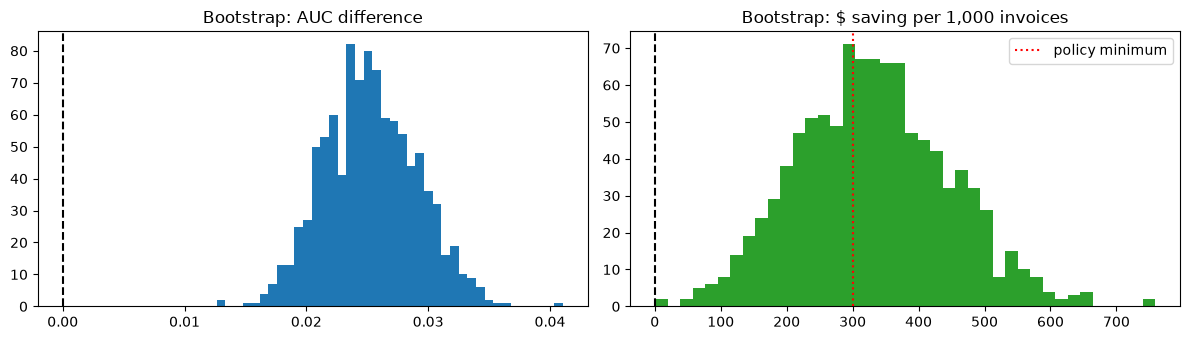

In [9]:
oot_proba = {name: fitted[name].predict_proba(X_oot)[:, 1] for name in ["champion_logreg", "challenger_hgb"]}
y_oot_arr = y_oot.to_numpy()
cust_codes, cust_index = np.unique(oot["customer_id"], return_inverse=True)
rows_by_customer = [np.flatnonzero(cust_index == c) for c in range(len(cust_codes))]   # invoice rows per customer


def paired_cluster_bootstrap(metric_fn, n_boot=CFG.n_bootstrap, seed=CFG.random_state):
    """Bootstrap distribution of metric(challenger) - metric(champion), resampling whole customers."""
    rng = np.random.default_rng(seed)
    deltas = np.empty(n_boot)
    for b in range(n_boot):
        picked = rng.integers(0, len(rows_by_customer), len(rows_by_customer))      # customers with replacement
        idx = np.concatenate([rows_by_customer[c] for c in picked])
        deltas[b] = (metric_fn(y_oot_arr[idx], oot_proba["challenger_hgb"][idx], "challenger_hgb")
                     - metric_fn(y_oot_arr[idx], oot_proba["champion_logreg"][idx], "champion_logreg"))
    return deltas


auc_metric = lambda y, p, name: roc_auc_score(y, p)
saving_metric = lambda y, p, name: -cost_per_1000(y, p, best_threshold[name])       # saving = minus cost

t0 = time.perf_counter()
auc_deltas = paired_cluster_bootstrap(auc_metric)
saving_deltas = paired_cluster_bootstrap(saving_metric)
log.info("Bootstrap done in %.0fs", time.perf_counter() - t0)

oot_summary = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_oot, oot_proba[name]),
           "threshold": best_threshold[name],
           "cost_per_1000_usd": cost_per_1000(y_oot, oot_proba[name], best_threshold[name]),
           "calls_per_1000": 1000 * (oot_proba[name] >= best_threshold[name]).mean()}
    for name in oot_proba}).T
print(oot_summary.round(4))
print(f"\nNever calling would cost ${cost_per_1000(y_oot, np.zeros(len(y_oot)), 1.0):,.0f} per 1,000 invoices")

auc_ci = np.percentile(auc_deltas, [2.5, 97.5])
saving_ci = np.percentile(saving_deltas, [2.5, 97.5])
observed_saving = oot_summary.loc["champion_logreg", "cost_per_1000_usd"] - oot_summary.loc["challenger_hgb", "cost_per_1000_usd"]
print(f"\nAUC difference (challenger - champion): {auc_deltas.mean():+.4f}, 95% CI [{auc_ci[0]:+.4f}, {auc_ci[1]:+.4f}]")
print(f"Saving per 1,000 invoices: ${observed_saving:+,.0f}, 95% CI [${saving_ci[0]:+,.0f}, ${saving_ci[1]:+,.0f}]")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(auc_deltas, bins=40); axes[0].axvline(0, color="k", ls="--"); axes[0].set_title("Bootstrap: AUC difference")
axes[1].hist(saving_deltas, bins=40, color="tab:green"); axes[1].axvline(0, color="k", ls="--")
axes[1].axvline(POLICY.min_saving_per_1000_invoices_usd, color="red", ls=":", label="policy minimum")
axes[1].set_title("Bootstrap: $ saving per 1,000 invoices"); axes[1].legend()
plt.tight_layout(); plt.show()

These two histograms are the heart of the decision. The left one answers "is the ranking better?" (yes: the whole AUC interval is above 0). The right one answers "**is it worth money, and how sure are we?**": the challenger saves roughly $330 per 1,000 invoices, and the interval is above $0, but notice that it also contains values **below** the policy minimum of $300 (red line). The point estimate clears the bar, the interval only partly does. Section 12 applies the policy as it was written; a stricter policy ("the lower end of the interval must exceed $300") would answer "not yet, collect more data".

---
## 10. Segment check: does any customer group get worse?

An average improvement can hide a **regression for a specific group** (e.g. a region, a customer size, or a protected group in credit decisions). Before switching, teams check the main segments.

In [10]:
segment_rows = []
for column in ["industry", "company_size", "region"]:
    for value, part in oot.groupby(column):
        idx = part.index.to_numpy()
        if y_oot_arr[idx].min() == y_oot_arr[idx].max():
            continue                                                      # AUC undefined with one class
        auc_champ = roc_auc_score(y_oot_arr[idx], oot_proba["champion_logreg"][idx])
        auc_chall = roc_auc_score(y_oot_arr[idx], oot_proba["challenger_hgb"][idx])
        segment_rows.append({"segment": f"{column}={value}", "n_invoices": len(idx),
                             "auc_champion": auc_champ, "auc_challenger": auc_chall,
                             "delta": auc_chall - auc_champ})
segments = pd.DataFrame(segment_rows).sort_values("delta")
large_segments = segments[segments["n_invoices"] >= 1000]          # small segments are too noisy for a rule
worst_segment = large_segments.iloc[0]
print(segments.round(3).to_string(index=False))

               segment  n_invoices  auc_champion  auc_challenger  delta
       industry=retail        1729         0.765           0.776  0.011
industry=manufacturing        1509         0.758           0.769  0.011
  industry=hospitality        1004         0.771           0.784  0.013
    company_size=large        1350         0.709           0.724  0.015
   industry=healthcare         916         0.736           0.751  0.015
 industry=construction         998         0.756           0.771  0.015
         industry=tech        1135         0.692           0.710  0.018
          region=north        1907         0.721           0.742  0.021
           region=west        1744         0.731           0.753  0.021
          region=south        1885         0.714           0.739  0.025
   company_size=medium        3181         0.720           0.745  0.026
    company_size=small        2760         0.703           0.730  0.027
           region=east        1755         0.681           0.713

Segment AUCs on a few hundred invoices are **noisy** (a delta of ±0.02 can easily be chance), so this check is a **guard rail**, not a precise measurement: a large drop in a big segment would block the switch and trigger an investigation.

---
## 11. Engineering constraints: latency, size, interpretability

A model that is 1% better but 20× slower, 100× bigger or impossible to explain may still be the wrong choice. We measure:
- **Latency**: time to score **one** invoice (the invoicing system calls the model online). We report the median and the 95th percentile (p95): users feel the slow requests.
- **Throughput**: invoices per second in a big batch.
- **Size**: the pickled pipeline in MB (memory, container size, load time).
- **Interpretability**: can we explain a single decision to the collections team or an auditor?

In [11]:
def measure_engineering(model, X_sample, n_single=200) -> dict:
    """Latency (single row), batch throughput and serialized size of a fitted pipeline."""
    single = X_sample.iloc[[0]]
    model.predict_proba(single)                                     # warm-up call (first call is slower)
    latencies = []
    for i in range(n_single):
        row = X_sample.iloc[[i % len(X_sample)]]
        t0 = time.perf_counter()
        model.predict_proba(row)
        latencies.append((time.perf_counter() - t0) * 1000)        # milliseconds
    t0 = time.perf_counter()
    model.predict_proba(X_sample)
    batch_seconds = time.perf_counter() - t0
    return {"latency_p50_ms": np.percentile(latencies, 50), "latency_p95_ms": np.percentile(latencies, 95),
            "batch_rows_per_sec": len(X_sample) / batch_seconds,
            "size_mb": len(pickle.dumps(model)) / 1e6}


t0 = time.perf_counter()
engineering = pd.DataFrame({name: measure_engineering(fitted[name], X_oot) for name in fitted}).T
engineering["interpretability"] = {"champion_logreg": "high: one coefficient per feature",
                                   "challenger_hgb": "medium: needs SHAP / permutation importance",
                                   "alt_random_forest": "medium: needs SHAP / permutation importance"}
engineering["oot_roc_auc"] = scheme_table["OOT test (truth)"]
log.info("Engineering measurements done in %.0fs", time.perf_counter() - t0)
print(engineering.round(3).to_string())

2026-10-21 18:02:12,243 | INFO | Engineering measurements done in 8s


                   latency_p50_ms  latency_p95_ms  batch_rows_per_sec  size_mb                             interpretability  oot_roc_auc
champion_logreg             5.409           6.298          656773.773    0.003            high: one coefficient per feature        0.712
challenger_hgb              6.670           7.692          139677.482    0.179  medium: needs SHAP / permutation importance        0.737
alt_random_forest          21.963          25.163           37251.435   66.072  medium: needs SHAP / permutation importance        0.695


Typical picture: logistic regression is tiny and fast; gradient boosting is still small and fast enough for an online API; the random forest is by far the **largest** model, and in our run it does not beat the gradient-boosting model on the out-of-time test either, so it drops out of the race.

(Absolute latency numbers depend on the machine and on how busy it is. In production you would measure them under realistic load, on the real serving hardware.)

---
## 12. The champion/challenger decision and the selection report

Now we apply the policy from Section 1, rule by rule, and write a **selection report**: a short document that records *what* was compared, *how*, the evidence, and the decision. It is attached to the model in the registry and read by reviewers, auditors, and your future self.

In [12]:
chall_eng = engineering.loc["challenger_hgb"]
checks = {   # bool(...) below turns NumPy booleans into plain Python booleans (needed for JSON)
    f"OOT saving >= ${POLICY.min_saving_per_1000_invoices_usd:.0f} per 1,000 invoices":
        observed_saving >= POLICY.min_saving_per_1000_invoices_usd,
    "95% CI of the saving above $0": (saving_ci[0] > 0) or not POLICY.require_ci_above_zero,
    f"p95 latency <= {POLICY.max_p95_latency_ms:.0f} ms": chall_eng["latency_p95_ms"] <= POLICY.max_p95_latency_ms,
    f"model size <= {POLICY.max_model_size_mb:.0f} MB": chall_eng["size_mb"] <= POLICY.max_model_size_mb,
    f"no large segment AUC drop > {POLICY.max_segment_auc_drop}": worst_segment["delta"] >= -POLICY.max_segment_auc_drop,
}
checks = {rule: bool(ok) for rule, ok in checks.items()}
decision = "PROMOTE challenger_hgb to champion" if all(checks.values()) else "KEEP champion_logreg"
for rule, ok in checks.items():
    print(f"[{'PASS' if ok else 'FAIL'}] {rule}")
print("\nDECISION:", decision)

[PASS] OOT saving >= $300 per 1,000 invoices
[PASS] 95% CI of the saving above $0
[PASS] p95 latency <= 100 ms
[PASS] model size <= 50 MB
[PASS] no large segment AUC drop > 0.03

DECISION: PROMOTE challenger_hgb to champion


In [13]:
report = f"""# Model selection report: invoice late-payment model
Date: {datetime.now(timezone.utc):%Y-%m-%d} | Author: data science team | scikit-learn {sklearn.__version__}

## Question
Should `challenger_hgb` (HistGradientBoosting) replace `champion_logreg` (logistic regression)?

## Data and validation
- Development period: {dev['issue_date'].min():%Y-%m-%d} to {dev['issue_date'].max():%Y-%m-%d} ({len(dev):,} invoices).
- Out-of-time test: {oot['issue_date'].min():%Y-%m-%d} to {oot['issue_date'].max():%Y-%m-%d} ({len(oot):,} invoices).
- Random KFold was rejected: it was more optimistic than grouped CV for every model, by far the most for the random forest (customers leak across folds).
- Model comparison: 5x5 repeated GroupKFold by customer; Nadeau-Bengio corrected paired t-test.

## Evidence
| | champion_logreg | challenger_hgb |
|---|---|---|
| Repeated grouped CV ROC-AUC | {cv_scores['champion_logreg'].mean():.4f} | {cv_scores['challenger_hgb'].mean():.4f} |
| OOT ROC-AUC | {oot_summary.loc['champion_logreg', 'ROC-AUC']:.4f} | {oot_summary.loc['challenger_hgb', 'ROC-AUC']:.4f} |
| OOT cost per 1,000 invoices | ${oot_summary.loc['champion_logreg', 'cost_per_1000_usd']:,.0f} | ${oot_summary.loc['challenger_hgb', 'cost_per_1000_usd']:,.0f} |
| p95 latency (ms) | {engineering.loc['champion_logreg', 'latency_p95_ms']:.1f} | {engineering.loc['challenger_hgb', 'latency_p95_ms']:.1f} |
| Size (MB) | {engineering.loc['champion_logreg', 'size_mb']:.2f} | {engineering.loc['challenger_hgb', 'size_mb']:.2f} |

- CV AUC difference {diffs.mean():+.4f}, corrected p-value {corr_p:.3g} (naive p-value {naive_p:.2g}, not used).
- OOT saving ${observed_saving:+,.0f} per 1,000 invoices, 95% cluster-bootstrap CI [${saving_ci[0]:+,.0f}, ${saving_ci[1]:+,.0f}].
- Worst segment: {worst_segment['segment']} (AUC delta {worst_segment['delta']:+.3f}, n={int(worst_segment['n_invoices'])}).

## Policy checks
""" + "\n".join(f"- [{'x' if ok else ' '}] {rule}" for rule, ok in checks.items()) + f"""

## Decision
**{decision}.**

## Follow-ups
- Monitor the late-payment rate and score drift monthly; the OOT period shows concept drift.
- If promoted: shadow-deploy for 4 weeks, then A/B test the call list before full rollout.
"""

REPORT_DIR = Path(tempfile.mkdtemp(prefix="model_selection_"))      # real life: the model registry entry
(REPORT_DIR / "selection_report.md").write_text(report)
(REPORT_DIR / "selection_decision.json").write_text(json.dumps(
    {"decision": decision, "checks": checks, "policy": asdict(POLICY),
     "oot_saving_per_1000_usd": round(float(observed_saving), 1),
     "oot_saving_ci_95": [round(float(v), 1) for v in saving_ci]}, indent=2))
print(report)
print("Saved to", REPORT_DIR)

# Model selection report: invoice late-payment model
Date: 2026-10-21 | Author: data science team | scikit-learn 1.9.0

## Question
Should `challenger_hgb` (HistGradientBoosting) replace `champion_logreg` (logistic regression)?

## Data and validation
- Development period: 2024-11-01 to 2026-04-20 (16,489 invoices).
- Out-of-time test: 2026-04-21 to 2026-10-21 (7,291 invoices).
- Random KFold was rejected: it was more optimistic than grouped CV for every model, by far the most for the random forest (customers leak across folds).
- Model comparison: 5x5 repeated GroupKFold by customer; Nadeau-Bengio corrected paired t-test.

## Evidence
| | champion_logreg | challenger_hgb |
|---|---|---|
| Repeated grouped CV ROC-AUC | 0.7304 | 0.7461 |
| OOT ROC-AUC | 0.7120 | 0.7372 |
| OOT cost per 1,000 invoices | $51,454 | $51,124 |
| p95 latency (ms) | 6.3 | 7.7 |
| Size (MB) | 0.00 | 0.18 |

- CV AUC difference +0.0157, corrected p-value 5.32e-05 (naive p-value 1.7e-12, not used).
- OOT saving $

**Why this is how mature teams work:**
- The decision is **reproducible** (the code produces the report) and **reviewable** (the evidence is in one place).
- The policy was fixed in advance, so nobody can cherry-pick metrics after the fact.
- Even when the challenger is promoted, it usually goes through **shadow mode** (it scores live traffic but its decisions are not used) and an **A/B test** before it fully replaces the champion; see `../11_ab_testing/`.
- If the challenger is *not* promoted, that is a **good outcome too**: you avoided a migration that would not have paid off, and you documented why.

---
## 13. Automated checks

Small tests that guard the evaluation code itself. A bug in a metric function can lead to a wrong decision, so it deserves tests as much as the model does.

In [14]:
def test_corrected_test_is_more_conservative():
    """The corrected p-value must never be smaller than the naive one for the same differences."""
    assert corr_p >= naive_p


def test_cost_function_edge_cases():
    y = np.array([1, 0, 1, 0])
    assert cost_per_1000(y, np.zeros(4), 0.5) == 1000 * 2 * CFG.cost_late_usd / 4        # never call
    assert cost_per_1000(y, np.ones(4), 0.5) == 1000 * (4 * CFG.cost_call_usd + 2 * CFG.cost_late_usd * 0.65) / 4


def test_no_time_leakage_between_dev_and_oot():
    assert dev["issue_date"].max() < oot["issue_date"].min()


def test_cluster_bootstrap_covers_all_rows():
    assert sum(len(r) for r in rows_by_customer) == len(oot)


def test_report_mentions_decision():
    assert decision in report


for test_fn in [test_corrected_test_is_more_conservative, test_cost_function_edge_cases,
                test_no_time_leakage_between_dev_and_oot, test_cluster_bootstrap_covers_all_rows,
                test_report_mentions_decision]:
    test_fn()
    print(f"PASSED  {test_fn.__name__}")

PASSED  test_corrected_test_is_more_conservative
PASSED  test_cost_function_edge_cases
PASSED  test_no_time_leakage_between_dev_and_oot
PASSED  test_cluster_bootstrap_covers_all_rows
PASSED  test_report_mentions_decision


---
## 14. Summary, exercises and resources

| Practice | What we did | Where it is used |
|---|---|---|
| Fix the selection policy first | `SelectionPolicy` dataclass | Avoids moving goalposts; model governance |
| Validation that matches production | Random vs grouped vs time-based CV, checked against an OOT test | Any data with repeat entities or time |
| Repeated, paired CV | 5 × 5 GroupKFold with shared seeds | Comparing candidate models |
| Correct statistics | Nadeau-Bengio corrected t-test (naive t-test is over-confident) | Model comparison in research and industry |
| Cluster bootstrap | Resample customers, not rows, for CIs on the OOT test | Correlated data (users, stores, patients) |
| Business metric | $ cost per 1,000 invoices at a cost-based threshold | Every decision-making model |
| Segment checks | AUC per industry / size / region | Fairness and robustness reviews |
| Engineering trade-offs | p95 latency, throughput, size, interpretability | Production readiness |
| Written decision | Markdown selection report + JSON decision | Model registry, audits |

### Practice exercises
1. Change `cost_late_usd` to $80. Does the decision change? Why does a smaller cost of lateness make model differences matter less?
2. Add the random forest to the repeated CV and the bootstrap. Would it pass the policy?
3. Replace the cluster bootstrap with a simple row-level bootstrap. How much narrower does the CI become, and why is that misleading?
4. Make the drift stronger in `simulate_invoices` (e.g. +1.5 for construction). Which validation scheme's estimate is now closest to the OOT truth?

### Resources
- scikit-learn example, *Statistical comparison of models using grid search* (Nadeau-Bengio corrected t-test, frequentist and Bayesian): https://scikit-learn.org/stable/auto_examples/model_selection/plot_grid_search_stats.html
- scikit-learn example, *Post-tuning the decision threshold for cost-sensitive learning*: https://scikit-learn.org/stable/auto_examples/model_selection/plot_cost_sensitive_learning.html
- Sebastian Raschka (2018), *Model Evaluation, Model Selection, and Algorithm Selection in Machine Learning*: https://arxiv.org/abs/1811.12808
- Nadeau & Bengio (2003), *Inference for the Generalization Error*, Machine Learning 52: https://link.springer.com/article/10.1023/A:1024068626366
- scikit-learn user guide, *Cross-validation: evaluating estimator performance* (GroupKFold, TimeSeriesSplit): https://scikit-learn.org/stable/modules/cross_validation.html

### Related notebooks
- Metrics and CV basics: `01_model_evaluation.ipynb`
- Hyperparameter search: `02_hyperparameter_optimization.ipynb`
- All the metrics in one place: `../10_evaluation_metrics_comprehensive.ipynb`
- Calibration: `../01_supervised/13_model_calibration.ipynb`
- A/B testing a new model: `../11_ab_testing/01_ab_testing.ipynb`
- Model registry: `../../15_MLOps/05_model_registry/`